# Evaporative MSMPR DPBE 
## Comentario previo a la lectura

El codigo tiene un par de extras que no se mencionan en el informe parcial, estos no han sido revisados como son las ecuaciones nucleación secundaria o el efecto de ripening. Dentro de los inputs se puede definir False para desabilitar estos extra. Además se prueba como afectaría una incorporación de impureza simple.


## Cambios en las relaciones del original

1. Se añade un coeficiente independiente de **transferencia de masa para disolución** P01, evitando identificarlo con k_g o con el Kd de partición de perclorato. Para esfera equivalente, m=rho_s*pi*L³/6 y A=pi*L²; si dm/dt=-A*k_d*(C_sat-C), entonces dL/dt=-2*k_d*(C_sat-C)/rho_s. Se aplica cuando C<C_sat(L), con unidades kg/m³ de líquido. Es un cierre de juguete de película, sin actividades ni resistencia superficial. El término devuelve masa al soluto mediante el mismo balance discreto. Con Gibbs–Thomson desactivado se conserva el comportamiento del original, que no disuelve.
2. El calor sensible usa una **densidad de solución de juguete de 1500 kg/m³**, separada de rho_w=1000 kg/m³ usada en el cierre de evaporación. Esta elección no se obtiene sumando el ensayo de especies. La aproximación hidráulica del original sigue sin balance de volumen de sólidos ni ecuación de estado.
3. Masas molares explícitas KNO₃=0.1011032 kg/mol y H₂O=0.0180153 kg/mol; conversión exacta 4184 J/kcal. Agua de refrigeración 19→21 °C para concordar con P17/P18 a 20 °C.
4. La malla inicial se aumenta a 320 celdas en 0–1 mm. Las verificaciones finales comparan 320/640 celdas y paso máximo 10/5 s, detectan truncamiento y conservan el criterio de régimen estacionario del original.

## Límites de interpretación

El balance sigue siendo isoterma impuesta y volumen líquido aproximado constante. C*, k_g, k_bp, k_bs, sus exponentes, k_d, alpha y Kd de perclorato no están calibrados. El cálculo de ppm supone mg/L para la entrada reportada; no verifica una especificación de producto. La búsqueda de temperatura y las sensibilidades describen solo este escenario hipotético. Las comprobaciones numéricas no validan la química o la planta.

Dependencias: NumPy, Matplotlib e IPython. Ejecutar desde la raíz del proyecto o desde `parametros`. Si el CSV está disponible se lee en cada ejecución; si no, se usa su instantánea embebida fechada **2026-10-06** con aviso explícito. El XLSX es una fotografía editable de estos valores y no controla automáticamente el notebook.


## 1. Entradas y procedencia

Concentraciones del soluto en kg/m³ de líquido, longitud equivalente en m, tiempo en s, temperatura en K para las leyes (diferencias en °C=K).

In [1]:
import copy
import math
import numpy as np
import matplotlib.pyplot as plt

# ---------- User-provided feed composition ----------
# g/L converts numerically to kg/m^3. These are the reported component values,
# not a charge-balanced species model or a complete thermodynamic description.
feed_composition = { # Promedio de concentraciones 
    "NaNO3_g_L": 639.5138122,
    "Cl_g_L": 142.2004963,
    "SO4_g_L": 34.74189922,
    "K_g_L": 231.1851307,
    "Ca_g_L": 1.824616788,
    "Mg_g_L": 32.1114745,
    "KClO4_IC_ppm_reported": 5.290858828,
    "ClO4_IC_ppm_reported": 3.799262673,
}

# ---------- Operating conditions (editable) ----------
BASE = {
    "volume_m3": 660, # Revisado
    "feed_flow_m3_s": 280.83/3600,  # Flujo reportado por la empresa -> 280.83 m3/h #Revisado
    "condensate_flow_kg_s": 0.010,  # pure evaporated/condensed solvent
    "water_density_kg_m3": 1000.0,  # illustrative water-like density
    "crystallizer_temperature_C": 40.0,
    "feed_temperature_C": 55.0,
    # NOT supplied as KNO3 data. Assumed solely to make this example run.
    "kno3_feed_assumed_kg_m3": 220.0,
    "feed_dilution_fraction": 0.0,  # C_feed,effective = C_feed*(1-d); 0 means undiluted.
    "initial_kno3_concentration_assumed_kg_m3": 220.0,
    # ---------- Explicit illustrative closures; calibrate before real use ----------
    "solubility_reference_assumed_kg_m3": 180.0,
    "solubility_reference_temperature_C": 40.0,
    "solubility_temperature_coefficient_assumed_per_C": 0.010,
    "growth_constant_assumed_m_s": 2.0e-7,
    "agitation_factor_assumed": 1.0,  # Illustrative multiplier; not a calibrated mixing model.
    "growth_exponent_assumed": 1.0,
    "nucleation_constant_assumed_per_m3_s": 1.0e10,
    "nucleation_exponent_assumed": 2.0,
    "crystal_density_assumed_kg_m3": 2100.0,
    "crystal_shape_factor_assumed": math.pi / 6.0,
    # Exploratory ClO4 model; verify ppm basis and calibrate Kd before use.
    "perchlorate_Kd_assumed": 0.01,  # PROVISIONAL — REQUIRES CALIBRATION
    "perchlorate_feed_kg_m3_assumed": feed_composition["ClO4_IC_ppm_reported"] * 1e-3,  # ppm assumed mg/L
    # Optional mechanisms: switch independently in this editable input section.
    "enable_secondary_nucleation": False,
    "secondary_nucleation_constant_assumed": 1.0e8,  # PROVISIONAL; calibrate.
    "secondary_supersaturation_exponent_assumed": 2.0,
    "secondary_solids_exponent_assumed": 1.0,
    "enable_gibbs_thomson_ripening": False,
    "gibbs_thomson_alpha_assumed_dimensionless": 10.0,  # PROVISIONAL; calibrate.
    # Energy/cooling-water inputs. Enthalpies are user-supplied values.
    "deltaH_crystallization_kcal_mol": -7.73,
    "deltaH_condensation_water_kcal_mol": -10.34,
    "solution_cp_assumed_J_kg_K": 2178.0,  # ESTIMADA A PARTIR DE CALCULO
    "cooling_water_cp_assumed_J_kg_K": 4182.0,  # REFERENCE / PROVISIONAL — REQUIRES VALIDATION.
    "cooling_water_density_assumed_kg_m3": 998.2,  # REFERENCE / PROVISIONAL — REQUIRES VALIDATION.
    "cooling_water_in_C": 19.0,
    "cooling_water_out_C": 21.5,
    # ---------- Numerical settings ----------
    "minimum_size_m": 0.0,
    "maximum_size_m": 1.0e-3,
    "number_of_size_bins": 320,
    "run_for_residence_times": 8.0,
    "maximum_step_s": 10.0,
    "cfl_safety_factor": 0.6,
}

print("Fixed-volume MSMPR learning model with isothermal energy accounting")
print(f"Crystallizer temperature: {BASE['crystallizer_temperature_C']} °C")
print(f"Feed temperature: {BASE['feed_temperature_C']} °C")
print("Secondary nucleation:", "ON" if BASE["enable_secondary_nucleation"] else "OFF")
print("Gibbs-Thomson ripening:", "ON" if BASE["enable_gibbs_thomson_ripening"] else "OFF")
print("Energy sign convention: positive heat load enters the vessel; positive cooling duty removes heat.")
print("KNO3 feed, solubility, growth and nucleation numbers are illustrative assumptions.")
print("Reported feed composition:")
for component, concentration in feed_composition.items():
    print(f"  {component}: {concentration}")

# Passive, nonvolatile tracers only; no impurity uptake closure is available.
# K is excluded: the crystallizing solute is already a KNO3-equivalent state.
# Reported perchlorate ppm cannot be converted without its concentration basis.
BASE["tracked_impurities"] = {
    name: {"feed_kg_m3": feed_composition[key],
           "initial_liquid_kg_m3": feed_composition[key]}
    for name, key in {"NaNO3": "NaNO3_g_L", "Cl": "Cl_g_L",
                      "SO4": "SO4_g_L", "Ca": "Ca_g_L", "Mg": "Mg_g_L"}.items()
}

Fixed-volume MSMPR learning model with isothermal energy accounting
Crystallizer temperature: 40.0 °C
Feed temperature: 55.0 °C
Secondary nucleation: OFF
Gibbs-Thomson ripening: OFF
Energy sign convention: positive heat load enters the vessel; positive cooling duty removes heat.
KNO3 feed, solubility, growth and nucleation numbers are illustrative assumptions.
Reported feed composition:
  NaNO3_g_L: 639.5138122
  Cl_g_L: 142.2004963
  SO4_g_L: 34.74189922
  K_g_L: 231.1851307
  Ca_g_L: 1.824616788
  Mg_g_L: 32.1114745
  KClO4_IC_ppm_reported: 5.290858828
  ClO4_IC_ppm_reported: 3.799262673


## 2. Caudal y residencia


In [2]:
def product_flow_m3_s(parameters):
    """Constant-volume closure: Q_product = Q_feed """
    return parameters["feed_flow_m3_s"]


def residence_time_s(parameters):
    """Nominal MSMPR residence time tau = vessel volume / product flow."""
    outlet_flow = product_flow_m3_s(parameters)
    if outlet_flow <= 0:
        raise ValueError("Condensate flow must be less than feed mass flow times water density.")
    return parameters["volume_m3"] / outlet_flow


print(f"Product slurry flow: {product_flow_m3_s(BASE):.6g} m³/s")
print(f"Nominal residence time: {residence_time_s(BASE)/60:.2f} min")

Product slurry flow: 0.0780083 m³/s
Nominal residence time: 141.01 min


## 3. Malla de tamaños


In [3]:
def make_size_grid(parameters):
    """Create equally spaced size-cell boundaries and cell centers."""
    size_edges = np.linspace(
        parameters["minimum_size_m"],
        parameters["maximum_size_m"],
        parameters["number_of_size_bins"] + 1,
    )
    cell_widths = np.diff(size_edges)
    size_centers = 0.5 * (size_edges[:-1] + size_edges[1:])
    return size_edges, size_centers, cell_widths


size_edges, size_centers, cell_widths = make_size_grid(BASE)
print("Number of bins:", len(size_centers))
print("First size-cell width:", cell_widths[0], "m")
print("Last size-cell boundary:", size_edges[-1], "m")

Number of bins: 320
First size-cell width: 3.125e-06 m
Last size-cell boundary: 0.001 m


## 4. Solubilidad, cinética y energía


In [4]:
def temperature(parameters):
    """Read the imposed, constant crystallizer temperature in kelvin."""
    return parameters["crystallizer_temperature_C"] + 273.15


def solubility(temperature_K, parameters):
    """Illustrative placeholder only: Cstar = Cref*exp[a*(T-Tref)]."""
    reference_temperature_K = parameters["solubility_reference_temperature_C"] + 273.15
    temperature_coefficient_per_K = parameters["solubility_temperature_coefficient_assumed_per_C"]
    return (parameters["solubility_reference_assumed_kg_m3"]
            * math.exp(temperature_coefficient_per_K * (temperature_K - reference_temperature_K)))


def supersaturation(concentration_kg_m3, temperature_K, parameters):
    """Return bulk S and nonnegative primary-kinetics supersaturation."""
    saturation_ratio = concentration_kg_m3 / solubility(temperature_K, parameters)
    return saturation_ratio, max(saturation_ratio - 1.0, 0.0)


def growth_rate(relative_excess, parameters):
    """Illustrative positive bulk growth law, in m/s."""
    return (parameters["growth_constant_assumed_m_s"]
            * parameters.get("agitation_factor_assumed", 1.0)
            * relative_excess ** parameters["growth_exponent_assumed"])


def nucleation_rate(relative_excess, parameters):
    """Primary nucleation, in crystals/(m³ slurry s)."""
    return (parameters["nucleation_constant_assumed_per_m3_s"]
            * parameters.get("agitation_factor_assumed", 1.0)
            * relative_excess ** parameters["nucleation_exponent_assumed"])


def secondary_nucleation_rate(relative_excess, solids_kg_m3, parameters):
    """Optional provisional Bsec = kb2*sigma**b2*Msolid**m."""
    if not parameters.get("enable_secondary_nucleation", False):
        return 0.0
    if solids_kg_m3 <= 0.0:
        return 0.0
    return (parameters["secondary_nucleation_constant_assumed"]
            * parameters.get("agitation_factor_assumed", 1.0)
            * relative_excess ** parameters["secondary_supersaturation_exponent_assumed"]
            * solids_kg_m3 ** parameters["secondary_solids_exponent_assumed"])


def gibbs_thomson_length_m(parameters):
    """Convert provisional molecular capillary length alpha to crystal length."""
    molecular_length = (parameters["kno3_molar_mass_kg_mol"] / (6.02214076e23
                       * parameters["crystal_density_assumed_kg_m3"]
                       * parameters["crystal_shape_factor_assumed"])) ** (1.0 / 3.0)
    return parameters["gibbs_thomson_alpha_assumed_dimensionless"] * molecular_length


def crystal_growth_profile(concentration_kg_m3, temperature_K, size_centers, parameters):
    """Signed size-specific growth; with ripening off recover the original scalar law."""
    bulk_cstar = solubility(temperature_K, parameters)
    if not parameters.get("enable_gibbs_thomson_ripening", False):
        _, excess = supersaturation(concentration_kg_m3, temperature_K, parameters)
        return np.full_like(size_centers, growth_rate(excess, parameters), dtype=float)
    gt_length = gibbs_thomson_length_m(parameters)
    size_cstar = bulk_cstar * np.exp(gt_length / np.maximum(size_centers, 1e-15))
    driving = concentration_kg_m3 / size_cstar - 1.0
    # P01 is a mass-transfer velocity; convert to diameter velocity for spheres.
    # Positive growth still uses P02/P03; dissolution uses the independent P01.
    growth = (parameters["growth_constant_assumed_m_s"]
              * parameters.get("agitation_factor_assumed", 1.0)
              * np.maximum(driving, 0.0) ** parameters["growth_exponent_assumed"])
    dissolution = (-2.0 * parameters["dissolution_mass_transfer_assumed_m_s"]
                   * parameters.get("agitation_factor_assumed", 1.0)
                   * np.maximum(size_cstar - concentration_kg_m3, 0.0)
                   / parameters["crystal_density_assumed_kg_m3"])
    return np.where(driving >= 0.0, growth, dissolution)


def critical_size_m(concentration_kg_m3, temperature_K, parameters):
    """Return Lcrit where size-specific saturation equals liquid concentration."""
    if not parameters.get("enable_gibbs_thomson_ripening", False):
        return np.nan
    ratio = concentration_kg_m3 / solubility(temperature_K, parameters)
    if ratio <= 1.0:
        return np.nan
    return gibbs_thomson_length_m(parameters) / np.log(ratio)


def calculate_thermal_loads(crystallization_rate_kg_s, parameters,
                            energy_accumulation_W=0.0):
    """Isothermal vessel heat balance and cooling water; positive Qload enters vessel.

    Feed sensible heat uses solution mass flow estimated from volumetric feed
    and the separate toy solution density (1500 kg/m3). Solution/cooling-water cp and
    cooling-water density are reference/provisional parameters requiring validation.
    Evaporation is counted once as latent heat removal; the crystallization
    source uses the model's existing signed KNO3 transfer rate.
    """
    kcal_to_J = 4184.0
    delta_h_cryst_J_mol = parameters["deltaH_crystallization_kcal_mol"] * kcal_to_J
    delta_h_vap_J_mol = -parameters["deltaH_condensation_water_kcal_mol"] * kcal_to_J
    kno3_mw_kg_mol = parameters["kno3_molar_mass_kg_mol"]
    water_mw_kg_mol = parameters["water_molar_mass_kg_mol"]
    q_crystallization_into_vessel = (
        -crystallization_rate_kg_s / kno3_mw_kg_mol * delta_h_cryst_J_mol)
    q_evaporation_removed = (
        parameters["condensate_flow_kg_s"] / water_mw_kg_mol * delta_h_vap_J_mol)
    feed_mass_flow = parameters["feed_flow_m3_s"] * parameters["solution_density_assumed_kg_m3"]
    q_sensible_feed = (feed_mass_flow * parameters["solution_cp_assumed_J_kg_K"]
                       * (parameters["feed_temperature_C"]
                          - parameters["crystallizer_temperature_C"]))
    # Qload = sensible + crystallization heat - latent removal - accumulation.
    residual_load = (q_sensible_feed + q_crystallization_into_vessel
                     - q_evaporation_removed - energy_accumulation_W)
    q_cooling = max(residual_load, 0.0)
    q_heating = max(-residual_load, 0.0)
    delta_t_cw = parameters["cooling_water_out_C"] - parameters["cooling_water_in_C"]
    if delta_t_cw <= 0.0:
        raise ValueError("Cooling-water outlet temperature must exceed inlet temperature.")
    cw_mass_flow = q_cooling / (parameters["cooling_water_cp_assumed_J_kg_K"] * delta_t_cw)
    cw_volume_flow = cw_mass_flow / parameters["cooling_water_density_assumed_kg_m3"]
    energy_residual = (q_sensible_feed + q_crystallization_into_vessel
                       - q_evaporation_removed - q_cooling + q_heating
                       - energy_accumulation_W)
    cw_residual = q_cooling - cw_mass_flow * parameters["cooling_water_cp_assumed_J_kg_K"] * delta_t_cw
    return {
        "Q_sensible_feed_W": q_sensible_feed,
        "Q_crystallization_into_vessel_W": q_crystallization_into_vessel,
        "Q_evaporation_removed_W": q_evaporation_removed,
        "Q_energy_accumulation_W": energy_accumulation_W,
        "Q_cooling_water_W": q_cooling,
        "Q_external_heating_required_W": q_heating,
        "cooling_water_delta_T_K": delta_t_cw,
        "cooling_water_mass_flow_kg_s": cw_mass_flow,
        "cooling_water_volume_flow_m3_s": cw_volume_flow,
        "cooling_water_volume_flow_m3_h": 3600.0 * cw_volume_flow,
        "energy_balance_residual_W": energy_residual,
        "cooling_water_balance_residual_W": cw_residual,
        "deltaH_crystallization_J_mol": delta_h_cryst_J_mol,
        "deltaH_vaporization_water_J_mol": delta_h_vap_J_mol,
    }

## 5. Balances y momentos


In [5]:
def pbe_rhs(number_density, growth_by_size_m_s, nucleation_per_m3_s,
            cell_widths, residence_time):
    """Signed-growth upwind PBE with boundary birth, size transport and MSMPR withdrawal."""
    n = len(number_density)
    face_growth = np.empty(n + 1)
    face_growth[0] = growth_by_size_m_s[0]
    face_growth[-1] = growth_by_size_m_s[-1]
    face_growth[1:-1] = 0.5 * (growth_by_size_m_s[:-1] + growth_by_size_m_s[1:])
    number_flux = np.empty(n + 1)
    number_flux[0] = nucleation_per_m3_s + min(face_growth[0], 0.0) * number_density[0]
    internal_positive = face_growth[1:-1] >= 0.0
    number_flux[1:-1] = np.where(
        internal_positive,
        face_growth[1:-1] * number_density[:-1],
        face_growth[1:-1] * number_density[1:])
    number_flux[-1] = max(face_growth[-1], 0.0) * number_density[-1]
    growth_change = -np.diff(number_flux) / cell_widths
    outlet_change = -number_density / residence_time
    return growth_change + outlet_change, growth_change


def mass_balance(concentration, feed_flow, feed_concentration, product_flow,
                 volume, crystallization_rate_kg_s):
    """dC/dt = (Qfeed*Cfeed - Qproduct*C - crystal production)/V."""
    return (feed_flow * feed_concentration - product_flow * concentration
            - crystallization_rate_kg_s) / volume


def effective_feed_concentration(parameters):
    """Apply proportional dilution to the inlet solute concentration only."""
    fraction = float(parameters.get("feed_dilution_fraction", 0.0))
    if not np.isfinite(fraction) or not 0.0 <= fraction < 1.0:
        raise ValueError("Feed dilution fraction must be finite and in [0, 1).")
    concentration = float(parameters["kno3_feed_assumed_kg_m3"])
    if not np.isfinite(concentration) or concentration < 0.0:
        raise ValueError("Inlet KNO3 concentration must be finite and nonnegative.")
    return concentration * (1.0 - fraction)


def calculate_moments(number_density, size_centers, cell_widths):
    """Approximate mu0...mu4 by a transparent cell-center sum."""
    return np.array([
        np.sum(number_density * size_centers**order * cell_widths)
        for order in range(5)
    ])


def crystallization_rate_kg_s(number_density, size_centers, cell_widths,
                              growth_m_s, parameters):
    """Legacy scalar-growth moment equation, retained for direct comparisons."""
    mu2 = calculate_moments(number_density, size_centers, cell_widths)[2]
    return (3.0 * parameters["volume_m3"]
            * parameters["crystal_shape_factor_assumed"]
            * parameters["crystal_density_assumed_kg_m3"]
            * growth_m_s * mu2)

## 6. Masa de cristales


In [6]:
def crystal_mass_concentration(number_density, size_centers, cell_widths, parameters):
    """rho_c * kv * mu3, in kg crystal / m³ slurry (cell-center quadrature)."""
    mu3 = calculate_moments(number_density, size_centers, cell_widths)[3]
    return (parameters["crystal_density_assumed_kg_m3"]
            * parameters["crystal_shape_factor_assumed"] * mu3)


def crystal_mass_flow(result):
    """Representative MSMPR product: Qp * crystal concentration, in kg/s."""
    return product_flow_m3_s(result["parameters"]) * crystal_mass_concentration(
        result["number_density"], result["centers"], result["widths"], result["parameters"])

## 7. Simulación


In [7]:
def calculate_csd_metrics(number_density, parameters, size_edges,
                          size_centers, cell_widths):
    """Calculate size moments, volume percentiles, number and solids concentration."""
    moments = calculate_moments(number_density, size_centers, cell_widths)
    if moments[0] <= 0 or moments[3] <= 0:
        return {"mean_number_size_um": np.nan, "D10_um": np.nan,
                "D50_um": np.nan, "D90_um": np.nan,
                "total_number": 0.0, "solids_kg_m3": 0.0}

    mean_size = moments[1] / moments[0]
    # Each cell is treated as constant n. Its exact L^3 integral gives its weight.
    volume_weights = number_density * (size_edges[1:]**4 - size_edges[:-1]**4) / 4.0
    cumulative_volume = np.cumsum(volume_weights)
    percentiles_m = []
    for fraction in (0.10, 0.50, 0.90):
        target = fraction * cumulative_volume[-1]
        cell = min(np.searchsorted(cumulative_volume, target), len(number_density) - 1)
        prior = cumulative_volume[cell - 1] if cell else 0.0
        within_cell_fraction = (target - prior) / volume_weights[cell]
        left, right = size_edges[cell], size_edges[cell + 1]
        percentile = (left**4 + within_cell_fraction * (right**4 - left**4))**0.25
        percentiles_m.append(percentile)

    volume = parameters["volume_m3"]
    crystal_density = parameters["crystal_density_assumed_kg_m3"]
    shape_factor = parameters["crystal_shape_factor_assumed"]
    return {
        "mean_number_size_um": mean_size * 1e6,
        "D10_um": percentiles_m[0] * 1e6,
        "D50_um": percentiles_m[1] * 1e6,
        "D90_um": percentiles_m[2] * 1e6,
        "total_number": volume * moments[0],
        "solids_kg_m3": shape_factor * crystal_density * moments[3],
    }


def simulate(parameters, maximum_steps=200000, observation_times_s=None):
    """Simulate crystal-free startup with optional secondary nucleation/ripening and energy history."""
    outlet_flow = product_flow_m3_s(parameters)
    if outlet_flow <= 0:
        raise ValueError("Product flow must be positive for continuous MSMPR operation.")
    dilution_fraction = float(parameters.get("feed_dilution_fraction", 0.0))
    if not np.isfinite(dilution_fraction) or not 0.0 <= dilution_fraction < 1.0:
        raise ValueError("Feed dilution fraction must be finite and in [0, 1).")
    agitation_factor = float(parameters.get("agitation_factor_assumed", 1.0))
    if not np.isfinite(agitation_factor) or agitation_factor <= 0.0:
        raise ValueError("Illustrative agitation factor must be finite and positive.")
    feed_concentration = effective_feed_concentration(parameters)
    residence_time = parameters["volume_m3"] / outlet_flow
    edges, centers, widths = make_size_grid(parameters)
    temperature_K = temperature(parameters)
    concentration = parameters["initial_kno3_concentration_assumed_kg_m3"]
    number_density = np.zeros(len(centers))
    duration = parameters["run_for_residence_times"] * residence_time
    # Normal runs retain their original sampling; sensitivity runs land exactly
    # on common observation times, even when the residence time changes.
    observation_index = 1
    if observation_times_s is not None:
        observation_times_s = np.asarray(observation_times_s, dtype=float)
        if (observation_times_s.ndim != 1 or len(observation_times_s) < 2
                or not np.all(np.isfinite(observation_times_s))
                or observation_times_s[0] != 0.0
                or np.any(np.diff(observation_times_s) <= 0.0)):
            raise ValueError("Observation times must start at zero and increase strictly.")
        duration = float(observation_times_s[-1])
    time = 0.0
    step_count = 0

    impurity_names = list(parameters.get("tracked_impurities", {}))
    impurity_feed = np.array([parameters["tracked_impurities"][name]["feed_kg_m3"]
                              for name in impurity_names]) * (1.0 - dilution_fraction)
    impurity_liquid = np.array([parameters["tracked_impurities"][name]["initial_liquid_kg_m3"]
                                for name in impurity_names])
    if (not np.all(np.isfinite(impurity_feed)) or np.any(impurity_feed < 0)
            or not np.all(np.isfinite(impurity_liquid)) or np.any(impurity_liquid < 0)):
        raise ValueError("Impurity feed and initial concentrations must be finite and nonnegative.")
    impurity_initial_mass = parameters["volume_m3"] * impurity_liquid.copy()
    liquid_out_mass = np.zeros(len(impurity_names))
    impurity_history = {key: [] for key in (
        "time_s", "liquid_kg_m3", "crystal_mass_flow_kg_s",
        "cumulative_liquid_out_kg", "mass_residual_kg")}
    trajectory = {key: [] for key in (
        "time_s", "concentration_kg_m3", "crystal_flow_kg_h", "D50_um",
        "S", "B_primary", "B_secondary",
        "B_total", "solids_kg_m3", "number_mean_um", "D43_um", "L_crit_m",
        "fraction_dissolving", "crystallization_kg_s", "Q_sensible_feed_W",
        "Q_crystallization_into_vessel_W", "Q_evaporation_removed_W",
        "Q_energy_accumulation_W", "Q_cooling_water_W",
        "Q_external_heating_required_W", "cooling_water_mass_flow_kg_s",
        "cooling_water_volume_flow_m3_s", "cooling_water_volume_flow_m3_h",
        "energy_balance_residual_W", "cooling_water_balance_residual_W")}
    trajectory["number_density_snapshots"] = []
    trajectory["growth_profiles_m_s"] = []
    next_sample = (residence_time / 20 if observation_times_s is None
                   else observation_times_s[observation_index])

    def current_state():
        saturation_ratio, excess = supersaturation(concentration, temperature_K, parameters)
        growth_by_size = crystal_growth_profile(concentration, temperature_K, centers, parameters)
        solid_concentration = crystal_mass_concentration(number_density, centers, widths, parameters)
        b_primary = nucleation_rate(excess, parameters)
        b_secondary = secondary_nucleation_rate(excess, solid_concentration, parameters)
        birth_total = b_primary + b_secondary
        dn, growth_dn = pbe_rhs(number_density, growth_by_size, birth_total, widths, residence_time)
        crystal_rate = (parameters["volume_m3"] * parameters["crystal_density_assumed_kg_m3"]
                        * parameters["crystal_shape_factor_assumed"]
                        * np.sum(growth_dn * centers**3 * widths))
        return (saturation_ratio, excess, growth_by_size, solid_concentration,
                b_primary, b_secondary, birth_total, dn, growth_dn, crystal_rate)

    def record():
        state = current_state()
        (saturation_ratio, excess, growth_by_size, solid_concentration,
         b_primary, b_secondary, birth_total, dn, growth_dn, crystal_rate) = state
        metrics_now = calculate_csd_metrics(number_density, parameters, edges, centers, widths)
        thermal = calculate_thermal_loads(crystal_rate, parameters, energy_accumulation_W=0.0)
        total_number = np.sum(number_density * widths)
        moments = calculate_moments(number_density, centers, widths)
        trajectory["time_s"].append(time)
        trajectory["concentration_kg_m3"].append(concentration)
        trajectory["crystal_flow_kg_h"].append(3600.0 * outlet_flow * solid_concentration)
        trajectory["D50_um"].append(metrics_now["D50_um"])
        trajectory["S"].append(saturation_ratio)
        trajectory["B_primary"].append(b_primary)
        trajectory["B_secondary"].append(b_secondary)
        trajectory["B_total"].append(birth_total)
        trajectory["solids_kg_m3"].append(solid_concentration)
        trajectory["number_mean_um"].append(moments[1] / max(moments[0], 1e-300) * 1e6)
        trajectory["D43_um"].append(moments[4] / max(moments[3], 1e-300) * 1e6)
        trajectory["L_crit_m"].append(critical_size_m(concentration, temperature_K, parameters))
        trajectory["fraction_dissolving"].append(
            np.sum(number_density[growth_by_size < 0] * widths[growth_by_size < 0])
            / max(total_number, 1e-300))
        trajectory["crystallization_kg_s"].append(crystal_rate)
        for key, value in thermal.items():
            if key in trajectory:
                trajectory[key].append(value)
        trajectory["number_density_snapshots"].append(number_density.copy())
        trajectory["growth_profiles_m_s"].append(growth_by_size.copy())

        impurity_history["time_s"].append(time)
        impurity_history["liquid_kg_m3"].append(impurity_liquid.copy())
        impurity_history["crystal_mass_flow_kg_s"].append(product_flow_m3_s(parameters)
            * solid_concentration)
        impurity_history["cumulative_liquid_out_kg"].append(liquid_out_mass.copy())
        impurity_history["mass_residual_kg"].append(
            impurity_initial_mass + time * parameters["feed_flow_m3_s"] * impurity_feed
            - parameters["volume_m3"] * impurity_liquid - liquid_out_mass)

    record()
    while time < duration:
        state = current_state()
        (_, _, growth_by_size, _, _, _, _, derivative_n,
         growth_derivative_n, crystal_rate) = state
        derivative_concentration = mass_balance(
            concentration, parameters["feed_flow_m3_s"],
            feed_concentration, outlet_flow,
            parameters["volume_m3"], crystal_rate)
        max_growth = np.max(np.abs(growth_by_size))
        step = min(parameters["maximum_step_s"],
                   parameters["cfl_safety_factor"] * np.min(widths)
                   / max(max_growth, 1e-300))
        step = min(step, 0.6 / (max_growth / np.min(widths) + 1.0 / residence_time))
        if derivative_concentration < 0 and concentration > 0:
            step = min(step, 0.5 * concentration / -derivative_concentration)
        step = min(step, duration - time)
        if observation_times_s is not None:
            step = min(step, next_sample - time)

        impurity_out_rate = outlet_flow * impurity_liquid
        liquid_out_mass += step * impurity_out_rate
        impurity_liquid += step * (parameters["feed_flow_m3_s"] * impurity_feed
                                   - impurity_out_rate) / parameters["volume_m3"]
        number_density = number_density + step * derivative_n
        concentration = concentration + step * derivative_concentration
        if (not np.all(np.isfinite(number_density)) or not np.isfinite(concentration)
                or np.any(number_density < 0) or concentration < 0):
            raise ValueError("Nonfinite or negative state; reduce the time step.")
        time += step
        step_count += 1
        if time >= next_sample or time >= duration:
            record()
            if observation_times_s is None:
                next_sample += residence_time / 20
            else:
                observation_index += 1
                if observation_index < len(observation_times_s):
                    next_sample = observation_times_s[observation_index]
        if step_count >= maximum_steps:
            raise RuntimeError("Reached maximum steps. Increase the limit or review assumptions.")

    saturation_ratio, relative_excess = supersaturation(concentration, temperature_K, parameters)
    metrics = calculate_csd_metrics(number_density, parameters, edges, centers, widths)
    metrics.update({"supersaturation_ratio": saturation_ratio,
                    "relative_supersaturation": relative_excess,
                    "KNO3_liquid_concentration_kg_m3": concentration,
                    "residence_time_s": residence_time,
                    "steps": step_count,
                    "mass_fraction_in_largest_bin": (
                        number_density[-1] * (edges[-1]**4 - edges[-2]**4)
                        / max(np.sum(number_density * (edges[1:]**4 - edges[:-1]**4)), 1e-300))})
    impurity_history = {key: np.asarray(values) for key, values in impurity_history.items()}
    impurity_history.update(names=impurity_names, initial_mass_kg=impurity_initial_mass,
                            feed_kg_m3=impurity_feed)
    trajectory = {key: np.asarray(values) for key, values in trajectory.items()}
    return {"impurity_history": impurity_history, "trajectory": trajectory,
            "parameters": parameters, "edges": edges, "centers": centers,
            "widths": widths, "number_density": number_density,
            "metrics": metrics, "time_s": time}

## 8. Caso base


In [8]:
baseline_parameters = copy.deepcopy(BASE)
baseline = simulate(baseline_parameters)

print("Illustrative baseline outputs")
for name, value in baseline["metrics"].items():
    print(f"{name}: {value:.5g}")

if baseline["metrics"]["mass_fraction_in_largest_bin"] > 0.001:
    print("WARNING: increase maximum_size_m and number_of_size_bins; the size domain may truncate the CSD.")

plt.figure(figsize=(7, 4))
plt.plot(baseline["centers"] * 1e6, baseline["number_density"], label="Baseline n(L)")
plt.xlabel("Crystal size L (µm)")
plt.ylabel("Number density n(L) (crystals m⁻⁴)")
plt.title("Baseline crystal size distribution")
plt.grid(alpha=0.25)
plt.legend()
plt.show()
 
def volume_fraction_density_q3(n,L,dL):
    raw=L**3*n; norm=float(np.sum(raw*dL))
    if not np.isfinite(norm) or norm<=0: raise ValueError("Cannot normalize q3 for empty CSD.")
    q3=raw/norm; integral=float(np.sum(q3*dL))
    if not np.isclose(integral,1.,rtol=1e-10,atol=1e-12): raise ArithmeticError(f"q3 integral={integral}")
    return q3,integral

q3_m_inv,q3_integral=volume_fraction_density_q3(baseline["number_density"],baseline["centers"],baseline["widths"])
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(baseline["centers"]*1e6,q3_m_inv*1e-6,label="Baseline q₃(L)")
ax.set(xlabel="Crystal size L (µm)",ylabel="Volume fraction density q₃ (µm⁻¹)",
       title="Baseline volume fraction density versus crystal size")
ax.grid(alpha=.25);ax.legend();fig.tight_layout();plt.show()
print(f"q₃ normalization integral: {q3_integral:.12f}")

def size_fraction_density_qk(n,L,dL,k):
    raw=L**k*n; norm=float(np.sum(raw*dL))
    if not np.isfinite(norm) or norm<=0: raise ValueError(f"Cannot normalize q{k} for empty CSD.")
    q=raw/norm; integral=float(np.sum(q*dL))
    if not np.isclose(integral,1.,rtol=1e-10,atol=1e-12): raise ArithmeticError(f"q{k} integral={integral}")
    return q,integral

q1_m_inv,q1_integral=size_fraction_density_qk(baseline["number_density"],baseline["centers"],baseline["widths"],1)
q2_m_inv,q2_integral=size_fraction_density_qk(baseline["number_density"],baseline["centers"],baseline["widths"],2)
q3_m_inv,q3_integral=size_fraction_density_qk(baseline["number_density"],baseline["centers"],baseline["widths"],3)

fig,axes=plt.subplots(1,3,figsize=(18,4),sharex=True)
axes[0].plot(baseline["centers"]*1e6,q1_m_inv*1e-6,label="Baseline q₁(L)")
axes[0].set(xlabel="Crystal size L (µm)",ylabel="Length fraction density q₁ (µm⁻¹)",
            title="Length fraction density versus crystal size")
axes[1].plot(baseline["centers"]*1e6,q2_m_inv*1e-6,label="Baseline q₂(L)")
axes[1].set(xlabel="Crystal size L (µm)",ylabel="Area fraction density q₂ (µm⁻¹)",
            title="Area fraction density versus crystal size")
axes[2].plot(baseline["centers"]*1e6,q3_m_inv*1e-6,label="Baseline q₃(L)")
axes[2].set(xlabel="Crystal size L (µm)",ylabel="Volume fraction density q₃ (µm⁻¹)",
            title="Volume fraction density versus crystal size")
for ax in axes:
    ax.grid(alpha=.25);ax.legend()
fig.tight_layout();plt.show()
print(f"q₁ normalization integral: {q1_integral:.12f}")
print(f"q₂ normalization integral: {q2_integral:.12f}")
print(f"q₃ normalization integral: {q3_integral:.12f}")


KeyError: 'kno3_molar_mass_kg_mol'

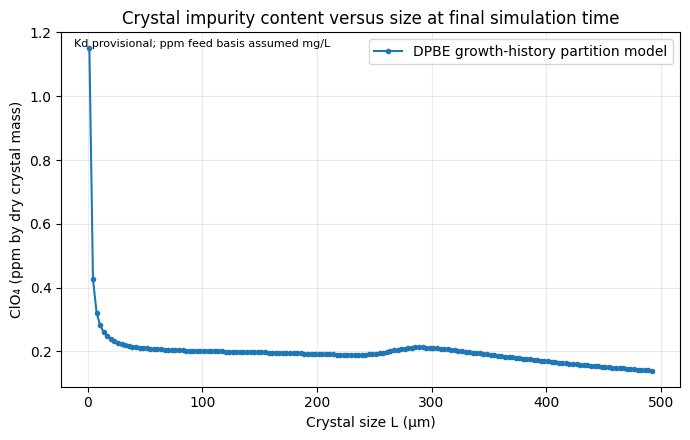

Crystal impurity profile follows saved DPBE growth history; no size law imposed.
Provisional Kd: 0.01 — requires calibration


In [ ]:
def calculate_perchlorate_size_history(result):
    p=result["parameters"]; tr=result["trajectory"]
    times=np.asarray(tr["time_s"]); ns=np.asarray(tr["number_density_snapshots"])
    gs=np.asarray(tr["growth_profiles_m_s"]); cs=np.asarray(tr["concentration_kg_m3"])
    L=result["centers"]; dL=result["widths"]
    rho_kv=p["crystal_density_assumed_kg_m3"]*p["crystal_shape_factor_assumed"]
    kd=p["perchlorate_Kd_assumed"]; feed=p["perchlorate_feed_kg_m3_assumed"]*(1.0-p.get("feed_dilution_fraction",0.0))
    qprod=product_flow_m3_s(p); tau=residence_time_s(p); cp=feed; q=np.zeros_like(L); profiles=[]
    for k in range(len(times)):
        host=rho_kv*L**3*ns[k]
        ratio=np.divide(q,host,out=np.full_like(q,np.nan),where=host>0)
        profiles.append(1e6*ratio/(1+ratio))
        if k==len(times)-1: break
        t=times[k]; t1=times[k+1]
        while t<t1-1e-10:
            gm=max(float(np.max(np.abs(gs[k]))),float(np.max(np.abs(gs[k+1]))),1e-30)
            dt=min(p["maximum_step_s"],t1-t,p["cfl_safety_factor"]*np.min(dL)/gm,.6/(gm/np.min(dL)+1/tau))
            f=min(max((t+.5*dt-times[k])/(t1-times[k]),0.),1.)
            nn=(1-f)*ns[k]+f*ns[k+1]; g=(1-f)*gs[k]+f*gs[k+1]; ck=max((1-f)*cs[k]+f*cs[k+1],1e-30)
            faces=np.zeros(len(L)+1)
            for j,vel in enumerate(g):
                if vel>=0: faces[j+1]+=vel*q[j]
                else: faces[j]+=vel*q[j]
            transport=-(faces[1:]-faces[:-1])/dL
            host=rho_kv*L**3*nn
            rcur=np.divide(q,host,out=np.zeros_like(q),where=host>0)
            dm=3*rho_kv*L**2*g
            transfer=nn*np.where(dm>=0,kd*cp/ck,rcur)*dm
            dq=transport+transfer-q/tau
            dcp=(p["feed_flow_m3_s"]*feed-qprod*cp-p["volume_m3"]*float(np.sum((transport+transfer)*dL)))/p["volume_m3"]
            qn=q+dt*dq; cn=cp+dt*dcp
            if np.any(qn < -1e-10) or cn < -1e-10 or not np.all(np.isfinite(qn)):
                raise ValueError("Impurity history became negative/nonfinite; reduce timestep.")
            q=np.maximum(qn,0); cp=max(cn,0); t+=dt
    return {"final_ppm_dry":profiles[-1],"profiles_ppm_dry":np.asarray(profiles),
            "centers_m":L,"number_density":ns[-1],"time_s":times,"Kd":kd}

def plot_perchlorate_vs_size(history):
    val=history["final_ppm_dry"]; weight=history["number_density"]*history["centers_m"]**3
    mask=np.isfinite(val)&(weight>1e-5*max(float(np.max(weight)),1e-300))
    fig,ax=plt.subplots(figsize=(7,4.5))
    ax.plot(history["centers_m"][mask]*1e6,val[mask],"o-",ms=3,label="DPBE growth-history partition model")
    ax.set(xlabel="Crystal size L (µm)",ylabel="ClO₄ (ppm by dry crystal mass)",
           title="Crystal impurity content versus size at final simulation time")
    ax.text(.02,.98,"Kd provisional; ppm feed basis assumed mg/L",transform=ax.transAxes,va="top",fontsize=8)
    ax.grid(alpha=.25);ax.legend();fig.tight_layout();return fig,ax

perchlorate_size_history=calculate_perchlorate_size_history(baseline)
perchlorate_size_fig,perchlorate_size_ax=plot_perchlorate_vs_size(perchlorate_size_history)
plt.show()
print("Crystal impurity profile follows saved DPBE growth history; no size law imposed.")
print("Provisional Kd:",perchlorate_size_history["Kd"],"— requires calibration")


In [ ]:
def plot_optional_physics_diagnostics(result):
    """Plot rate/size/ripening diagnostics and the cooling-water heat balance."""
    tr = result["trajectory"]
    time_h = tr["time_s"] / 3600.0
    fig, axes = plt.subplots(3, 2, figsize=(14, 13))
    axes[0, 0].plot(time_h, tr["B_primary"], label="Primary")
    axes[0, 0].plot(time_h, tr["B_secondary"], label="Secondary")
    axes[0, 0].plot(time_h, tr["B_total"], linestyle="--", label="Total")
    axes[0, 0].set(ylabel="Nucleation rate (crystals m⁻³ s⁻¹)", title="Nucleation")
    axes[0, 0].legend()
    axes[0, 1].plot(time_h, tr["solids_kg_m3"])
    axes[0, 1].set(ylabel="Solids concentration (kg/m³ slurry)", title="Crystal inventory")
    axes[1, 0].plot(time_h, tr["number_mean_um"], label="Number mean")
    axes[1, 0].plot(time_h, tr["D43_um"], label="D43")
    axes[1, 0].set(ylabel="Characteristic size (µm)", title="Size metrics")
    axes[1, 0].legend()
    axes[1, 1].plot(time_h, tr["fraction_dissolving"], label="Population dissolving")
    if result["parameters"].get("enable_gibbs_thomson_ripening", False):
        axes[1, 1].plot(time_h, tr["L_crit_m"] * 1e6, label="Critical size (µm)")
    axes[1, 1].set(ylabel="Fraction / size (µm)", title="Gibbs–Thomson ripening")
    axes[1, 1].legend()
    axes[2, 0].plot(time_h, tr["Q_sensible_feed_W"] / 1000, label="Feed sensible")
    axes[2, 0].plot(time_h, tr["Q_crystallization_into_vessel_W"] / 1000,
                    label="Crystallization released")
    axes[2, 0].plot(time_h, tr["Q_evaporation_removed_W"] / 1000,
                    label="Evaporation removed")
    axes[2, 0].plot(time_h, tr["Q_cooling_water_W"] / 1000,
                    label="Cooling-water duty")
    axes[2, 0].set(xlabel="Simulation time (h)", ylabel="Heat rate (kW)", title="Energy terms")
    axes[2, 0].legend(fontsize=8)
    axes[2, 1].plot(time_h, tr["cooling_water_mass_flow_kg_s"], label="kg/s")
    ax2 = axes[2, 1].twinx()
    ax2.plot(time_h, tr["cooling_water_volume_flow_m3_h"], color="C1", label="m³/h")
    axes[2, 1].set(xlabel="Simulation time (h)", ylabel="Cooling water (kg/s)",
                   title="Cooling-water requirement")
    ax2.set_ylabel("Cooling water (m³/h)")
    lines, labels = axes[2, 1].get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    axes[2, 1].legend(lines + lines2, labels + labels2)
    for ax in axes.flat:
        ax.grid(alpha=0.25)
    fig.suptitle("Optional nucleation, ripening, energy and cooling-water diagnostics")
    fig.tight_layout()
    return fig, axes


#diagnostic_fig, diagnostic_axes = plot_optional_physics_diagnostics(baseline)
#plt.show()
tr = baseline["trajectory"]
print("Thermal closure (energy and cooling-water residuals):",
      f"{np.max(np.abs(tr['energy_balance_residual_W'])):.3e} W,",
      f"{np.max(np.abs(tr['cooling_water_balance_residual_W'])):.3e} W")
print("Cooling water range:", f"{np.min(tr['cooling_water_mass_flow_kg_s']):.4g}–"
      f"{np.max(tr['cooling_water_mass_flow_kg_s']):.4g} kg/s;",
      f"{np.min(tr['cooling_water_volume_flow_m3_h']):.4g}–"
      f"{np.max(tr['cooling_water_volume_flow_m3_h']):.4g} m³/h")
print("Energy accumulation is zero because vessel temperature is imposed/isothermal.")
print("Thermophysical heat capacities and cooling-water density are reference/provisional inputs.")

Thermal closure (energy and cooling-water residuals): 0.000e+00 W, 9.313e-10 W
Cooling water range: 731.3–1595 kg/s; 2637–5751 m³/h
Energy accumulation is zero because vessel temperature is imposed/isothermal.
Thermophysical heat capacities and cooling-water density are reference/provisional inputs.


## 9. Estado estacionario


In [ ]:
def check_solution(result):
    """Small, explicit final-state checks; return reasons to reject a run."""
    p, m = result["parameters"], result["metrics"]
    n, L, dL = result["number_density"], result["centers"], result["widths"]
    C = m["KNO3_liquid_concentration_kg_m3"]
    tau, Qp = residence_time_s(p), product_flow_m3_s(p)
    excess = max(m["supersaturation_ratio"] - 1, 0)
    solid_for_birth=crystal_mass_concentration(n,L,dL,p)
    birth=nucleation_rate(excess,p)+secondary_nucleation_rate(excess,solid_for_birth,p)
    dn, growth_dn = pbe_rhs(
        n, crystal_growth_profile(C, temperature(p), L, p), birth, dL, tau)
    solid_C = crystal_mass_concentration(n, L, dL, p)
    formation = (p["volume_m3"] * p["crystal_density_assumed_kg_m3"]
                 * p["crystal_shape_factor_assumed"] * np.sum(growth_dn * L**3 * dL))
    feed_solute = p["feed_flow_m3_s"] * effective_feed_concentration(p)
    dC = (feed_solute - Qp*C - formation) / p["volume_m3"]
    residual_n = tau * np.sum(np.abs(dn)*dL) / max(np.sum(n*dL), 1.0)
    residual_C = tau * abs(dC) / max(C, 1.0)
    balance_error = abs(feed_solute - Qp*C - crystal_mass_flow(result)) / max(feed_solute, 1e-12)
    m.update(residual_per_tau=max(residual_n, residual_C), balance_error=balance_error)
    reasons = []
    if not (np.all(np.isfinite(n)) and np.isfinite(C) and np.all(n >= 0) and C >= 0):
        reasons.append("nonfinite/negative state")
    if not 0 <= solid_C / p["crystal_density_assumed_kg_m3"] < 1:
        reasons.append("invalid solid volume fraction")
    if max(residual_n, residual_C) > 1e-3:
        reasons.append("not steady")
    if balance_error > 1e-3:
        reasons.append("solute balance")
    if m["mass_fraction_in_largest_bin"] > 1e-3:
        reasons.append("size domain too short")
    if solid_C > 0 and not (0 <= m["D10_um"] <= m["D50_um"] <= m["D90_um"] <= result["edges"][-1]*1e6):
        reasons.append("invalid percentiles")
    return reasons


def steady_run(parameters):
    """Try longer startup runs; never silently label an unconverged state steady."""
    p = copy.deepcopy(parameters)
    try:
        for duration in (8, 16, 32):
            p["run_for_residence_times"] = duration
            result = simulate(p)
            reasons = check_solution(result)
            if not reasons:
                break
        m = result["metrics"]
        return dict(temperature_C=p["crystallizer_temperature_C"],
                    crystal_flow_kg_h=3600*crystal_mass_flow(result),
                    D10_um=m["D10_um"], D50_um=m["D50_um"], D90_um=m["D90_um"],
                    S=m["supersaturation_ratio"], valid=not reasons,
                    status=", ".join(reasons) or "passed", result=result)
    except (ValueError, RuntimeError, OverflowError) as error:
        return dict(temperature_C=p["crystallizer_temperature_C"],
                    crystal_flow_kg_h=np.nan, D10_um=np.nan, D50_um=np.nan,
                    D90_um=np.nan, S=np.nan, valid=False, status=str(error))


def run_at_temperature(temperature_C, parameters=BASE):
    """Change only imposed vessel temperature; retain existing closures."""
    p = copy.deepcopy(parameters)
    p["crystallizer_temperature_C"] = float(temperature_C)
    return steady_run(p)


def temperature_sensitivity(temperatures_C, parameters=BASE):
    return [run_at_temperature(T, parameters) for T in temperatures_C]

## 10. Sensibilidad


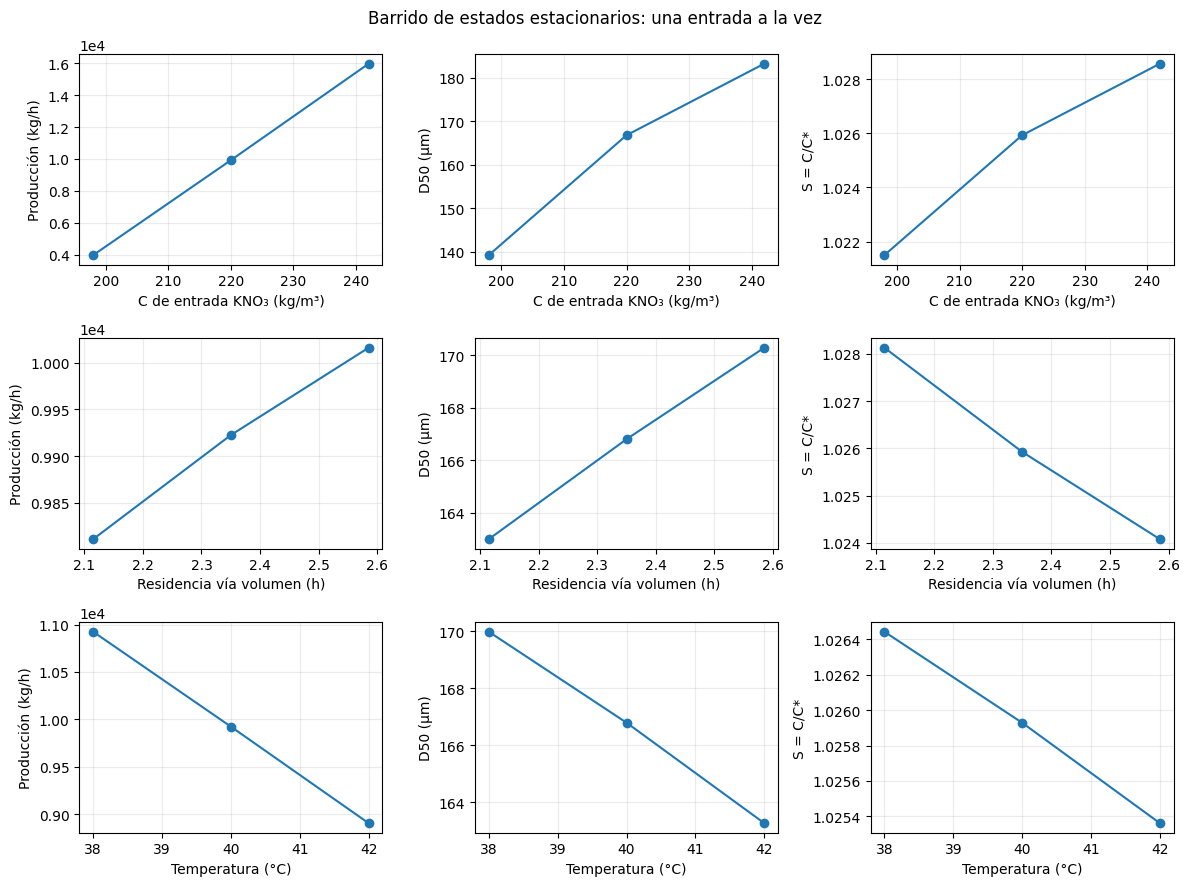

In [ ]:
# Una sola configuración para todas las figuras de sensibilidad.
SENSITIVITY_INPUTS = [
    {"name": "kno3_feed_assumed_kg_m3", "label": "C de entrada KNO₃ (kg/m³)",
     "short_label": "C de entrada", "sweep_step": 0.10 * BASE["kno3_feed_assumed_kg_m3"],
     "derivative_step": 0.01 * BASE["kno3_feed_assumed_kg_m3"]},
    {"name": "residence_time", "label": "Residencia vía volumen (h)",
     "short_label": "Residencia", "sweep_step": 0.10 * residence_time_s(BASE),
     "derivative_step": 0.01 * residence_time_s(BASE)},
    {"name": "crystallizer_temperature_C", "label": "Temperatura (°C)",
     "short_label": "Temperatura", "sweep_step": 2.0, "derivative_step": 0.2},
]


def input_value(parameters, name):
    """Valor de la entrada en las unidades usadas para perturbarla."""
    return residence_time_s(parameters) if name == "residence_time" else parameters[name]


def input_scale(parameters, name):
    """Escala relativa: temperatura absoluta y demás entradas en su unidad natural."""
    return temperature(parameters) if name == "crystallizer_temperature_C" else input_value(parameters, name)


def perturb_input(parameters, name, offset):
    """Copiar el caso y cambiar solo una entrada independiente."""
    changed = copy.deepcopy(parameters)
    value = input_value(parameters, name) + offset
    if name == "residence_time":
        if value <= 0.0:
            raise ValueError("Residence time must be positive.")
        changed["volume_m3"] = value * product_flow_m3_s(changed)
    else:
        changed[name] = value
    return changed


def central_derivative(low_values, high_values, step):
    """Derivada central (unidades de salida / unidades de entrada)."""
    if not np.isfinite(step) or step <= 0.0:
        raise ValueError("Finite-difference step must be finite and positive.")
    return (np.asarray(high_values) - np.asarray(low_values)) / (2.0 * step)


baseline_steady = steady_run(BASE)
if not baseline_steady["valid"]:
    raise RuntimeError("Baseline is not steady: " + baseline_steady["status"])

output_keys = ["crystal_flow_kg_h", "D50_um", "S"]
output_labels = ["Producción (kg/h)", "D50 (µm)", "S = C/C*"]
sensitivity_results = {}
fig, axes = plt.subplots(len(SENSITIVITY_INPUTS), len(output_keys),
                         figsize=(12, 9), squeeze=False)
for row, specification in enumerate(SENSITIVITY_INPUTS):
    name, step = specification["name"], specification["sweep_step"]
    offsets = [-step, 0.0, step]
    runs = [steady_run(perturb_input(BASE, name, offset)) if offset else baseline_steady
            for offset in offsets]
    sensitivity_results[name] = runs
    values = np.array([input_value(BASE, name) + offset for offset in offsets])
    if name == "residence_time":
        values /= 3600.0
    for ax, key, ylabel in zip(axes[row], output_keys, output_labels):
        ax.plot(values, [run[key] if run["valid"] else np.nan for run in runs], "o-")
        ax.set(xlabel=specification["label"], ylabel=ylabel)
        ax.ticklabel_format(axis="both", style="sci", scilimits=(-3, 4), useOffset=False)
        ax.grid(alpha=0.25)
    for offset, run in zip(offsets, runs):
        if not run["valid"]:
            print(specification["label"], offset, "excluido:", run["status"])
fig.suptitle("Barrido de estados estacionarios: una entrada a la vez")
fig.tight_layout()
plt.show()

## 11. Barrido de temperatura


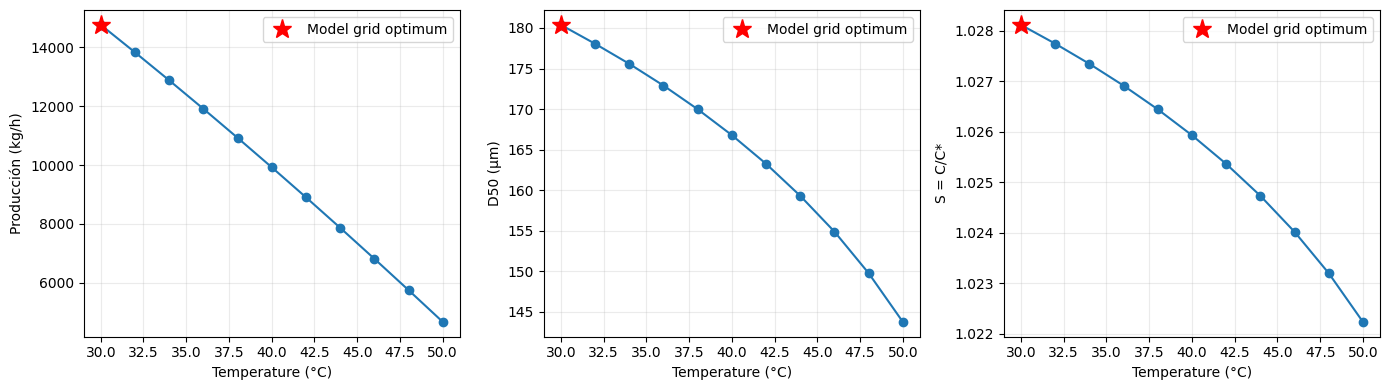

Numerical screening and volume-weighted CSD percentiles:
  30 °C | D10/D50/D90 = 85.71/180.38/328.07 µm | passed
  32 °C | D10/D50/D90 = 84.60/178.06/323.89 µm | passed
  34 °C | D10/D50/D90 = 83.43/175.58/319.37 µm | passed
  36 °C | D10/D50/D90 = 82.15/172.91/314.49 µm | passed
  38 °C | D10/D50/D90 = 80.76/169.99/309.16 µm | passed
  40 °C | D10/D50/D90 = 79.25/166.79/303.35 µm | passed
  42 °C | D10/D50/D90 = 77.57/163.26/296.94 µm | passed
  44 °C | D10/D50/D90 = 75.70/159.32/289.81 µm | passed
  46 °C | D10/D50/D90 = 73.60/154.90/281.73 µm | passed
  48 °C | D10/D50/D90 = 71.17/149.78/272.46 µm | passed
  50 °C | D10/D50/D90 = 68.32/143.78/261.55 µm | passed

Model grid optimum: 30 °C, 14757.64 kg/h.
This is a search boundary, not an identified interior optimum.


In [ ]:
temperature_results = temperature_sensitivity(np.arange(30.0, 50.1, 2.0))
accepted = [r for r in temperature_results if r["valid"]]
optimum = max(accepted, key=lambda r: r["crystal_flow_kg_h"]) if accepted else None

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, key, label in zip(axes, output_keys, output_labels):
    ax.plot([r["temperature_C"] for r in temperature_results],
            [r[key] if r["valid"] else np.nan for r in temperature_results], "o-")
    if optimum:
        ax.plot(optimum["temperature_C"], optimum[key], "r*", markersize=14,
                label="Model grid optimum")
        ax.legend()
    ax.set(xlabel="Temperature (°C)", ylabel=label)
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

print("Numerical screening and volume-weighted CSD percentiles:")
for r in temperature_results:
    print(f"{r['temperature_C']:4.0f} °C | D10/D50/D90 = "
          f"{r['D10_um']:.2f}/{r['D50_um']:.2f}/{r['D90_um']:.2f} µm | {r['status']}")

if optimum:
    print(f"\nModel grid optimum: {optimum['temperature_C']:.0f} °C, "
          f"{optimum['crystal_flow_kg_h']:.2f} kg/h.")
    if optimum["temperature_C"] in (30, 50):
        print("This is a search boundary, not an identified interior optimum.")
else:
    print("No accepted steady states: no optimum can be reported.")

In [ ]:
from IPython.display import Markdown, display

table = ["| Temperature (°C) | Crystal flow (kg/h) | D50 (µm) | Supersaturation S |",
         "|---:|---:|---:|---:|"]
for r in temperature_results:
    best = (r["valid"] and optimum is not None and
            np.isclose(r["crystal_flow_kg_h"], optimum["crystal_flow_kg_h"], rtol=1e-6))
    values = [f"{r['temperature_C']:.0f}", f"{r['crystal_flow_kg_h']:.2f}",
              f"{r['D50_um']:.2f}", f"{r['S']:.4f}"]
    if best:
        values = [f"**{v}**" for v in values]
    if not r["valid"]:
        values[0] += " (excluded)"
    table.append("| " + " | ".join(values) + " |")
display(Markdown("\n".join(table)))

| Temperature (°C) | Crystal flow (kg/h) | D50 (µm) | Supersaturation S |
|---:|---:|---:|---:|
| **30** | **14757.64** | **180.38** | **1.0281** |
| 32 | 13825.02 | 178.06 | 1.0277 |
| 34 | 12875.24 | 175.58 | 1.0273 |
| 36 | 11908.23 | 172.91 | 1.0269 |
| 38 | 10923.96 | 169.99 | 1.0264 |
| 40 | 9922.52 | 166.79 | 1.0259 |
| 42 | 8904.12 | 163.26 | 1.0254 |
| 44 | 7869.16 | 159.32 | 1.0247 |
| 46 | 6818.36 | 154.90 | 1.0240 |
| 48 | 5752.92 | 149.78 | 1.0232 |
| 50 | 4674.93 | 143.78 | 1.0222 |

## 12. Elasticidad local


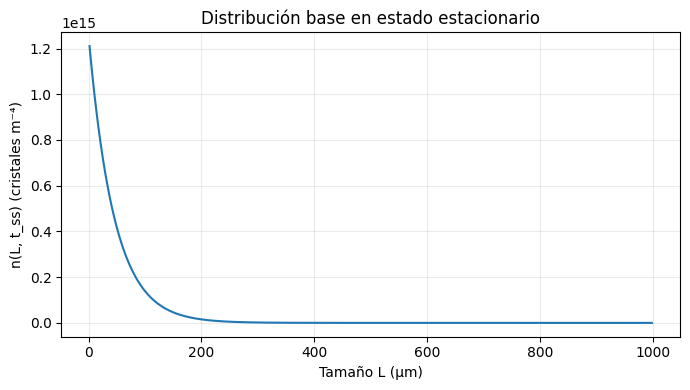

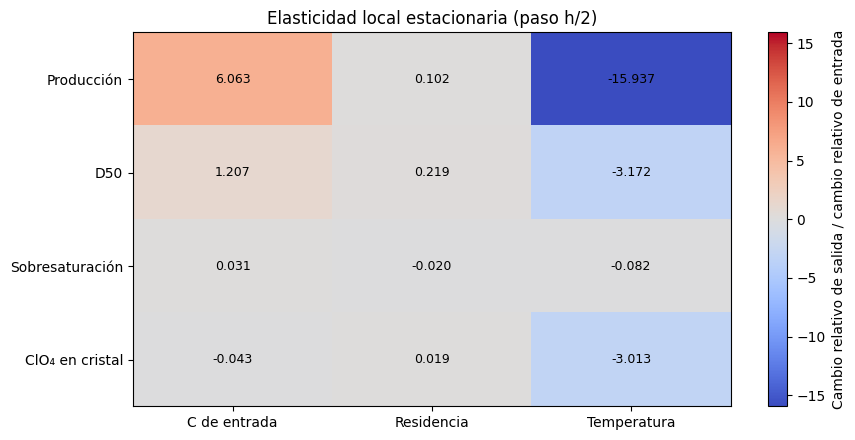

Elasticidades (filas: producción, D50, S, ClO₄; columnas: C entrada, residencia, T):
[[  6.062987   0.102369 -15.937059]
 [  1.207227   0.219386  -3.171669]
 [  0.031285  -0.019586  -0.082221]
 [ -0.042804   0.019354  -3.013021]]
Diferencia absoluta entre estimaciones con h y h/2:
[[1.0200e-04 6.0000e-06 6.0000e-06]
 [1.6629e-02 1.5000e-05 2.1900e-04]
 [1.9000e-05 1.0000e-06 2.0000e-06]
 [2.0000e-05 1.0000e-06 0.0000e+00]]


In [ ]:
steady_result = baseline_steady["result"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(steady_result["centers"] * 1e6, steady_result["number_density"])
ax.set(xlabel="Tamaño L (µm)", ylabel="n(L, t_ss) (cristales m⁻⁴)",
       title="Distribución base en estado estacionario")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

heatmap_outputs = [("crystal_flow_kg_h", "Producción"), ("D50_um", "D50"),
                   ("S", "Sobresaturación"), ("impurity_ppm", "ClO₄ en cristal")]
heatmap_inputs = [(item["name"], item["short_label"]) for item in SENSITIVITY_INPUTS]


def steady_output_values(run):
    """Vector de salidas; un estado no aceptado no produce sensibilidades válidas."""
    if not run["valid"]:
        return np.full(len(heatmap_outputs), np.nan)
    return np.array([steady_crystal_perchlorate_ppm(run) if key == "impurity_ppm"
                     else run[key] for key, _ in heatmap_outputs])


def plot_sensitivity_matrix(matrix, row_labels, column_labels, title, colorbar_label):
    """Mapa con escala simétrica: el color conserva signo y magnitud."""
    fig, ax = plt.subplots(figsize=(9, 4.5))
    finite_values = matrix[np.isfinite(matrix)]
    limit = max(float(np.max(np.abs(finite_values))) if finite_values.size else 0.0, 1e-12)
    image = ax.imshow(np.ma.masked_invalid(matrix), cmap="coolwarm", aspect="auto",
                      vmin=-limit, vmax=limit)
    ax.set_xticks(range(len(column_labels)), column_labels)
    ax.set_yticks(range(len(row_labels)), row_labels)
    ax.set_title(title)
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            value = matrix[row, column]
            ax.text(column, row, f"{value:.3f}" if np.isfinite(value) else "n/a",
                    ha="center", va="center", fontsize=9)
    fig.colorbar(image, ax=ax, label=colorbar_label)
    fig.tight_layout()
    plt.show()


baseline_outputs = steady_output_values(baseline_steady)
steady_local_results = {}
elasticities = np.full((len(heatmap_outputs), len(SENSITIVITY_INPUTS)), np.nan)
steady_step_errors = np.full_like(elasticities, np.nan)
for column, specification in enumerate(SENSITIVITY_INPUTS):
    name = specification["name"]
    estimates = []
    steady_local_results[name] = {}
    for step_factor in (1.0, 0.5):
        step = specification["derivative_step"] * step_factor
        runs = [steady_run(perturb_input(BASE, name, sign * step)) for sign in (-1, 1)]
        steady_local_results[name][step_factor] = runs
        for run in runs:
            if not run["valid"]:
                print(name, "estado excluido:", run["status"])
        derivative = central_derivative(steady_output_values(runs[0]),
                                        steady_output_values(runs[1]), step)
        estimate = np.full_like(derivative, np.nan)
        np.divide(input_scale(BASE, name) * derivative, baseline_outputs,
                  out=estimate, where=np.isfinite(baseline_outputs) & (baseline_outputs != 0.0))
        estimates.append(estimate)
    elasticities[:, column] = estimates[1]
    steady_step_errors[:, column] = np.abs(estimates[1] - estimates[0])

plot_sensitivity_matrix(elasticities, [label for _, label in heatmap_outputs],
                        [label for _, label in heatmap_inputs],
                        "Elasticidad local estacionaria (paso h/2)",
                        "Cambio relativo de salida / cambio relativo de entrada")
print("Elasticidades (filas: producción, D50, S, ClO₄; columnas: C entrada, residencia, T):")
print(np.round(elasticities, 6))
print("Diferencia absoluta entre estimaciones con h y h/2:")
print(np.round(steady_step_errors, 6))
if np.any(steady_step_errors > 0.05 * np.maximum(np.abs(elasticities), 0.1)):
    print("Aviso: algunas derivadas estacionarias dependen del paso; refinar antes de interpretarlas.")

## 13. Sensibilidad temporal


C de entrada paso final: 0.034375 (unidad de entrada); máximo error relativo de curvas: 0.69%; convergencia: True
Residencia paso final: 0.6609870740305523 (unidad de entrada); máximo error relativo de curvas: 0.28%; convergencia: True
Temperatura paso final: 0.00625 (unidad de entrada); máximo error relativo de curvas: 0.41%; convergencia: True


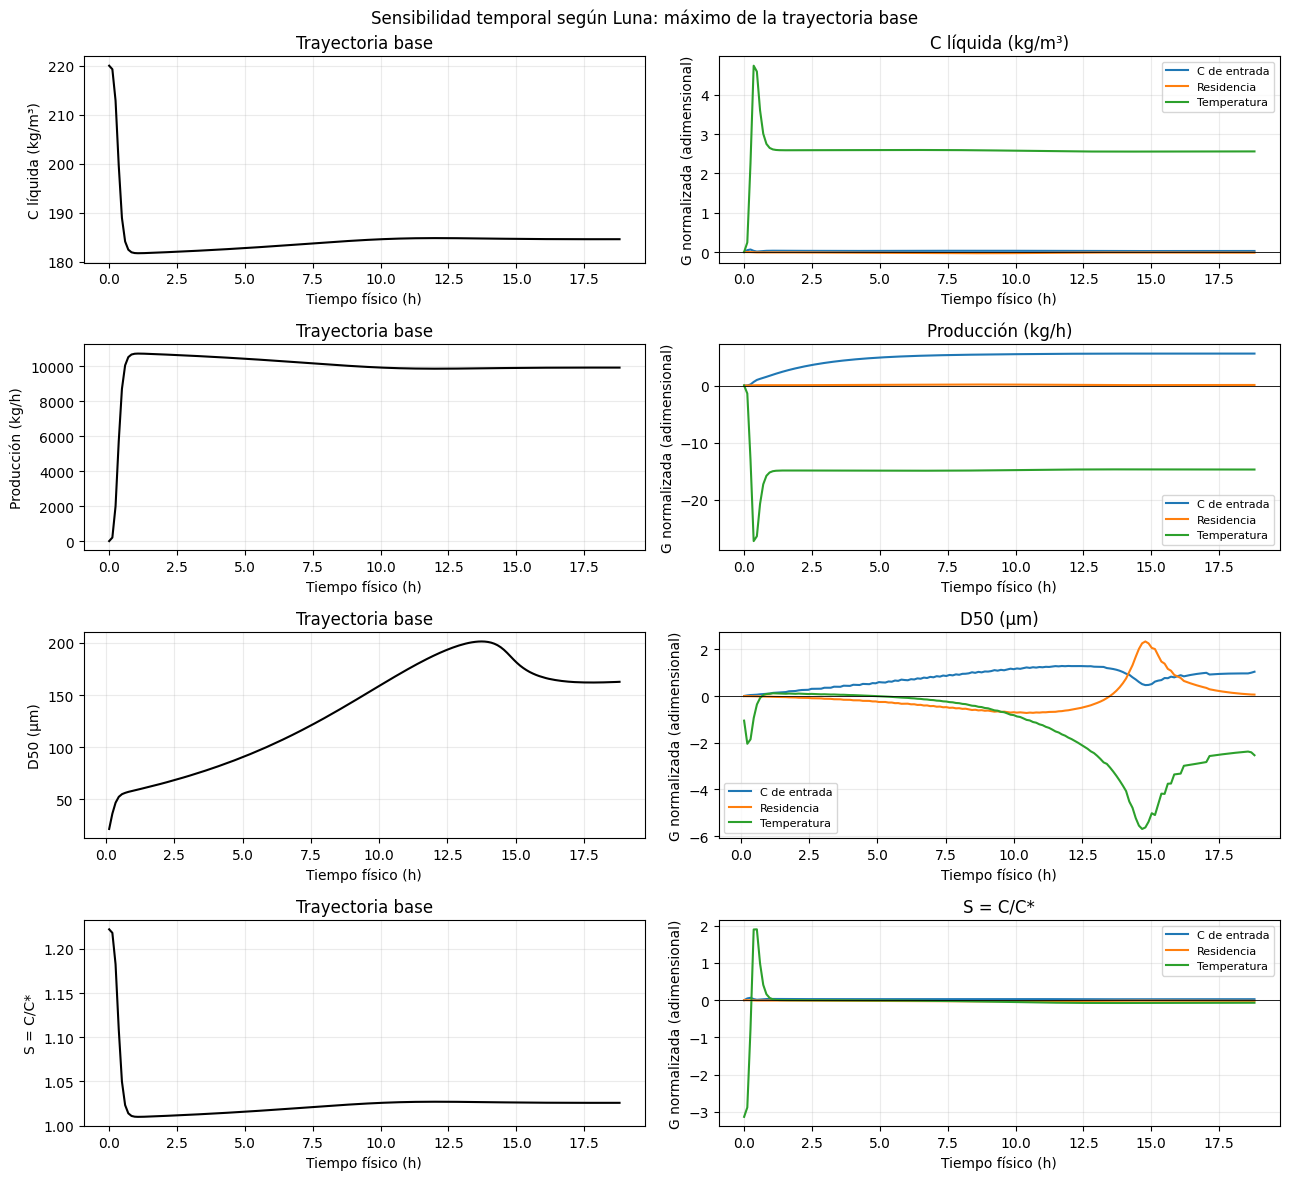

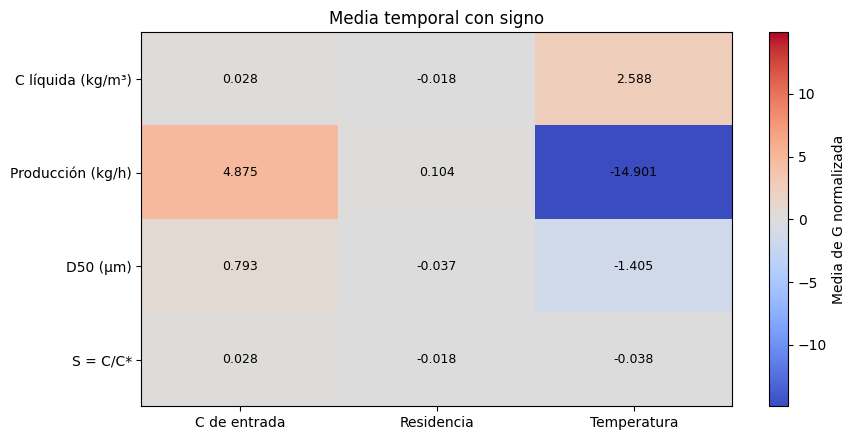

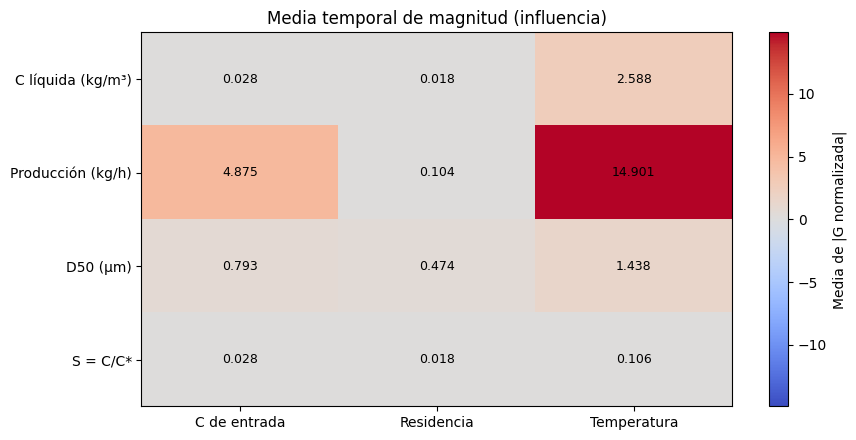

Máximos base usados como denominador: {'concentration_kg_m3': np.float64(220.0), 'crystal_flow_kg_h': np.float64(10731.16104035947), 'D50_um': np.float64(201.28736066494207), 'S': np.float64(1.2222222222222223)}
Máxima diferencia absoluta de G normalizada entre h y h/2:
[[0.0000e+00 0.0000e+00 2.0000e-06]
 [0.0000e+00 0.0000e+00 1.2000e-05]
 [8.8800e-03 6.5990e-03 2.3528e-02]
 [0.0000e+00 0.0000e+00 2.0000e-06]]
Media temporal con signo (C líquida, producción, D50, S × C entrada, residencia, T):
[[  0.028325  -0.018056   2.58816 ]
 [  4.875082   0.103957 -14.900836]
 [  0.792996  -0.037142  -1.405332]
 [  0.028325  -0.018056  -0.038296]]
Media temporal de magnitud:
[[ 0.028325  0.018056  2.58816 ]
 [ 4.875082  0.103957 14.900836]
 [ 0.792996  0.473851  1.438232]
 [ 0.028325  0.018056  0.106474]]
D50 en t=0 es indefinido; su promedio empieza en la primera observación con cristales.


In [ ]:
# Observaciones exactas y comunes en tiempo físico; no interpolar relojes distintos.
SENSITIVITY_TIMES_S = np.linspace(0.0, 8.0 * residence_time_s(BASE), 161)
dynamic_outputs = [("concentration_kg_m3", "C líquida (kg/m³)"),
                   ("crystal_flow_kg_h", "Producción (kg/h)"),
                   ("D50_um", "D50 (µm)"), ("S", "S = C/C*")]


def trajectory_values(result):
    """Matriz (tiempo, salida) de una trayectoria con los tiempos acordados."""
    times = result["trajectory"]["time_s"]
    if times.shape != SENSITIVITY_TIMES_S.shape or not np.allclose(
            times, SENSITIVITY_TIMES_S, rtol=0.0, atol=1e-8):
        raise ValueError("Sensitivity trajectories must use the same observation times.")
    return np.column_stack([result["trajectory"][key] for key, _ in dynamic_outputs])


def normalize_luna(absolute_sensitivity, parameter_scale, base_maxima):
    """Fórmula de Luna; no usar el máximo de cada trayectoria perturbada."""
    normalized = np.full_like(absolute_sensitivity, np.nan, dtype=float)
    np.divide(parameter_scale * absolute_sensitivity, base_maxima,
              out=normalized, where=np.isfinite(base_maxima) & (base_maxima > 0.0))
    return normalized


def temporal_average(times, values, absolute=False):
    """Promedio trapezoidal en el intervalo definido, sin unir huecos inválidos."""
    finite_indices = np.flatnonzero(np.isfinite(values))
    if len(finite_indices) < 2:
        return np.nan
    first, last = finite_indices[0], finite_indices[-1]
    selected = values[first:last + 1]
    if not np.all(np.isfinite(selected)):
        return np.nan
    if absolute:
        selected = np.abs(selected)
    intervals = np.diff(times[first:last + 1])
    integral = np.sum(0.5 * (selected[:-1] + selected[1:]) * intervals)
    return integral / (times[last] - times[first])


dynamic_baseline = simulate(copy.deepcopy(BASE), observation_times_s=SENSITIVITY_TIMES_S)
dynamic_base_values = trajectory_values(dynamic_baseline)
base_maxima = np.array([np.max(column[np.isfinite(column)])
                        if np.any(np.isfinite(column)) else np.nan
                        for column in dynamic_base_values.T])
# Error relativo de curvas en norma máxima; escala mínima para curvas casi nulas.
DYNAMIC_STEP_TOLERANCE = 0.01
MAX_STEP_REFINEMENTS = 8
dynamic_sensitivity_results = {}
mean_signed = np.full((len(dynamic_outputs), len(SENSITIVITY_INPUTS)), np.nan)
mean_absolute = np.full_like(mean_signed, np.nan)
dynamic_step_errors = np.full_like(mean_signed, np.nan)

for column, specification in enumerate(SENSITIVITY_INPUTS):
    name = specification["name"]
    estimates = []
    for refinement in range(MAX_STEP_REFINEMENTS):
        step = specification["derivative_step"] / (2.0 ** refinement)
        pair = [simulate(perturb_input(BASE, name, sign * step),
                         observation_times_s=SENSITIVITY_TIMES_S) for sign in (-1, 1)]
        derivative = central_derivative(trajectory_values(pair[0]), trajectory_values(pair[1]), step)
        normalized = normalize_luna(derivative, input_scale(BASE, name), base_maxima)
        estimates.append({"step": step, "absolute": derivative, "normalized": normalized})
        if len(estimates) < 2:
            continue
        coarse, fine = estimates[-2:]
        error = np.nanmax(np.abs(fine["normalized"] - coarse["normalized"]), axis=0)
        curve_scale = np.maximum(np.nanmax(np.abs(fine["normalized"]), axis=0), 0.1)
        relative_error = error / curve_scale
        if np.all(np.isfinite(relative_error)) and np.all(relative_error <= DYNAMIC_STEP_TOLERANCE):
            break
    converged = bool(np.all(relative_error <= DYNAMIC_STEP_TOLERANCE))
    dynamic_sensitivity_results[name] = {
        "coarse": coarse, "fine": fine, "relative_step_error": relative_error,
        "step_converged": converged,
    }
    print(specification["short_label"], "paso final:", fine["step"],
          "(unidad de entrada); máximo error relativo de curvas:",
          f"{np.max(relative_error):.2%}; convergencia: {converged}")
    for row in range(len(dynamic_outputs)):
        values = fine["normalized"][:, row]
        mean_signed[row, column] = temporal_average(SENSITIVITY_TIMES_S, values)
        mean_absolute[row, column] = temporal_average(SENSITIVITY_TIMES_S, values, absolute=True)
        difference = values - coarse["normalized"][:, row]
        finite_difference = difference[np.isfinite(difference)]
        if finite_difference.size:
            dynamic_step_errors[row, column] = np.max(np.abs(finite_difference))

fig, axes = plt.subplots(len(dynamic_outputs), 2, figsize=(13, 12), squeeze=False)
for row, (_, label) in enumerate(dynamic_outputs):
    axes[row, 0].plot(SENSITIVITY_TIMES_S / 3600.0, dynamic_base_values[:, row], color="k")
    axes[row, 0].set(xlabel="Tiempo físico (h)", ylabel=label, title="Trayectoria base")
    for specification in SENSITIVITY_INPUTS:
        values = dynamic_sensitivity_results[specification["name"]]["fine"]["normalized"][:, row]
        axes[row, 1].plot(SENSITIVITY_TIMES_S / 3600.0, values, label=specification["short_label"])
    axes[row, 1].axhline(0.0, color="k", linewidth=0.6)
    axes[row, 1].set(xlabel="Tiempo físico (h)", ylabel="G normalizada (adimensional)", title=label)
    axes[row, 1].legend(fontsize=8)
    for ax in axes[row]:
        ax.grid(alpha=0.25)
fig.suptitle("Sensibilidad temporal según Luna: máximo de la trayectoria base")
fig.tight_layout()
plt.show()

plot_sensitivity_matrix(mean_signed, [label for _, label in dynamic_outputs],
                        [item["short_label"] for item in SENSITIVITY_INPUTS],
                        "Media temporal con signo", "Media de G normalizada")
plot_sensitivity_matrix(mean_absolute, [label for _, label in dynamic_outputs],
                        [item["short_label"] for item in SENSITIVITY_INPUTS],
                        "Media temporal de magnitud (influencia)", "Media de |G normalizada|")
print("Máximos base usados como denominador:", dict(zip([key for key, _ in dynamic_outputs], base_maxima)))
print("Máxima diferencia absoluta de G normalizada entre h y h/2:")
print(np.round(dynamic_step_errors, 6))
print("Media temporal con signo (C líquida, producción, D50, S × C entrada, residencia, T):")
print(np.round(mean_signed, 6))
print("Media temporal de magnitud:")
print(np.round(mean_absolute, 6))
if not all(result["step_converged"] for result in dynamic_sensitivity_results.values()):
    print("Aviso: alguna curva no converge al 1% al reducir h; refinar antes de interpretarla.")
print("D50 en t=0 es indefinido; su promedio empieza en la primera observación con cristales.")

## 14. Respuesta a escalones


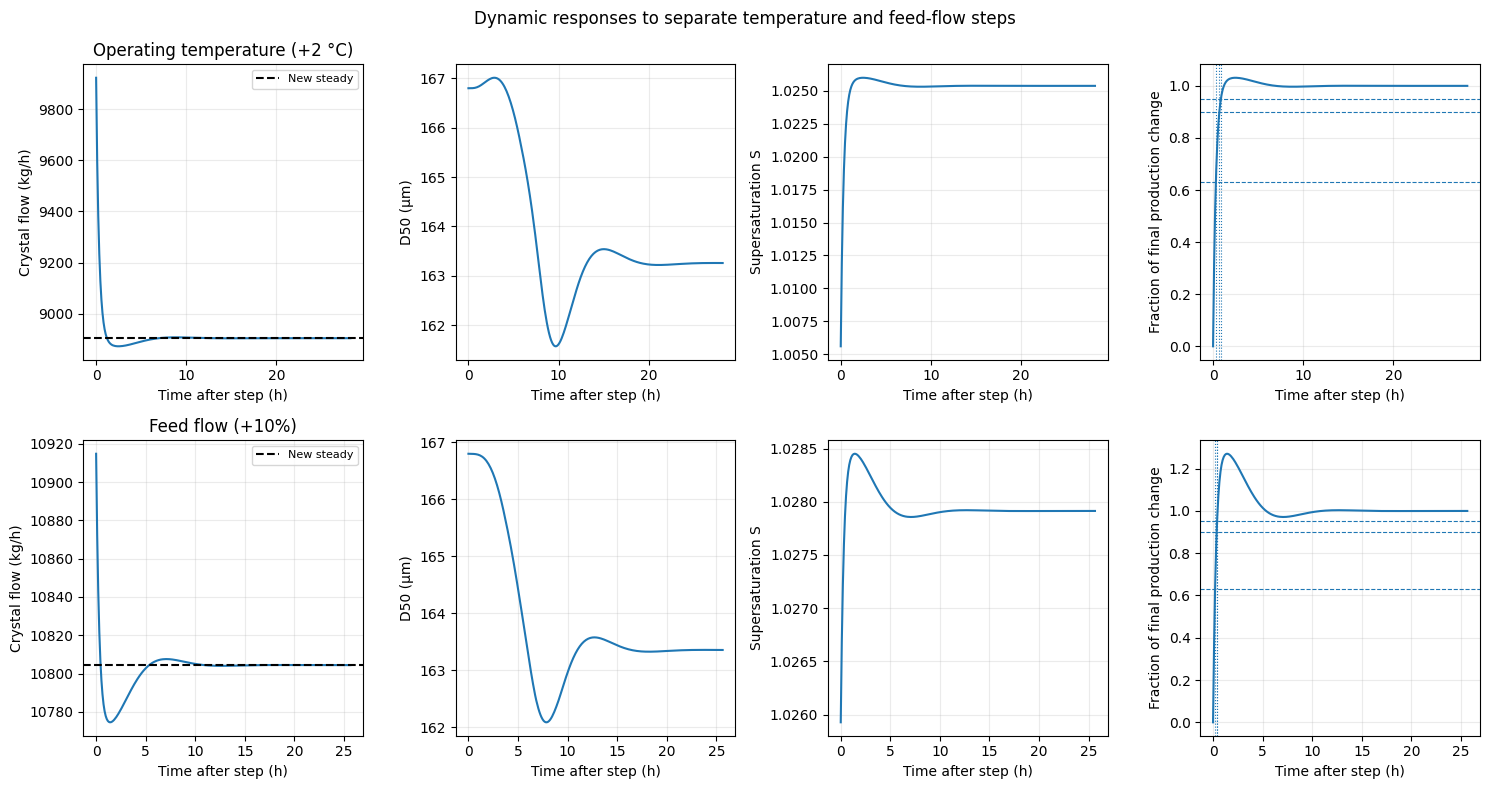

Baseline CSD steady-state startup time: 37.60 h.
Operating temperature (+2 °C): post-step hydraulic residence = 2.35 h.
  Production reached 63.2% of its final change after 0.32 h (0.13 post-step tau_h).
  Production reached 90.0% of its final change after 0.70 h (0.30 post-step tau_h).
  Production reached 95.0% of its final change after 0.87 h (0.37 post-step tau_h).
Feed flow (+10%): post-step hydraulic residence = 2.14 h.
  Production reached 63.2% of its final change after 0.21 h (0.10 post-step tau_h).
  Production reached 90.0% of its final change after 0.37 h (0.17 post-step tau_h).
  Production reached 95.0% of its final change after 0.41 h (0.19 post-step tau_h).


In [ ]:
def simulate_step_response(parameters, initial_result,
                           duration_residence_times=12, samples_per_residence=20):
    """Continue the PBE from a steady state after a step in operating conditions."""
    p = copy.deepcopy(parameters)
    outlet_flow = product_flow_m3_s(p)
    if outlet_flow <= 0:
        raise ValueError("Product flow must stay positive after the step.")
    tau_h = p["volume_m3"] / outlet_flow
    edges, centers, widths = make_size_grid(p)
    number_density = initial_result["number_density"].copy()
    concentration = initial_result["metrics"]["KNO3_liquid_concentration_kg_m3"]
    temperature_K = temperature(p)
    duration = duration_residence_times * tau_h
    sample_interval = tau_h / samples_per_residence
    next_sample = sample_interval
    time = 0.0
    history = {"time_s": [], "crystal_flow_kg_h": [], "D50_um": [],
               "S": [], "total_number": []}

    def record(sample_time):
        metrics = calculate_csd_metrics(number_density, p, edges, centers, widths)
        history["time_s"].append(sample_time)
        history["crystal_flow_kg_h"].append(
            3600 * outlet_flow * crystal_mass_concentration(number_density, centers, widths, p))
        history["D50_um"].append(metrics["D50_um"])
        history["S"].append(supersaturation(concentration, temperature_K, p)[0])
        history["total_number"].append(metrics["total_number"])

    record(0.0)
    steps = 0
    while time < duration:
        saturation_ratio, relative_excess = supersaturation(concentration, temperature_K, p)
        growth_by_size = crystal_growth_profile(concentration, temperature_K, centers, p)
        solids = crystal_mass_concentration(number_density, centers, widths, p)
        birth = (nucleation_rate(relative_excess, p)
                 + secondary_nucleation_rate(relative_excess, solids, p))
        derivative_n, growth_derivative_n = pbe_rhs(
            number_density, growth_by_size, birth, widths, tau_h)
        crystal_rate = (p["volume_m3"] * p["crystal_density_assumed_kg_m3"]
                        * p["crystal_shape_factor_assumed"]
                        * np.sum(growth_derivative_n * centers**3 * widths))
        derivative_concentration = mass_balance(
            concentration, p["feed_flow_m3_s"], effective_feed_concentration(p),
            outlet_flow, p["volume_m3"], crystal_rate)

        step = p["maximum_step_s"]
        max_growth = np.max(np.abs(growth_by_size))
        step = min(step, p["cfl_safety_factor"] * np.min(widths)
                   / max(max_growth, 1e-300))
        step = min(step, 0.6 / (max_growth / np.min(widths) + 1 / tau_h))
        if derivative_concentration < 0 and concentration > 0:
            step = min(step, 0.5 * concentration / -derivative_concentration)
        step = min(step, duration - time)
        number_density = number_density + step * derivative_n
        concentration = concentration + step * derivative_concentration
        if (not np.all(np.isfinite(number_density)) or not np.isfinite(concentration)
                or np.any(number_density < 0) or concentration < 0):
            raise ValueError("The step response became nonphysical; reduce the time step.")
        time += step
        steps += 1
        if time >= next_sample or time >= duration:
            record(time)
            next_sample += sample_interval
        if steps >= 200000:
            raise RuntimeError("Step response reached the maximum step count.")

    history["time_s"] = np.asarray(history["time_s"])
    for key in ("crystal_flow_kg_h", "D50_um", "S", "total_number"):
        history[key] = np.asarray(history[key])
    history["residence_time_s"] = tau_h
    return history


def first_time_to_fraction(times, values, final_value, fraction):
    """Interpolate the first crossing of a fraction of the total output change."""
    change = final_value - values[0]
    if abs(change) < 1e-12 * max(abs(values[0]), 1.0):
        return np.nan
    normalized = (values - values[0]) / change
    for i in range(1, len(times)):
        if normalized[i] >= fraction and normalized[i-1] < fraction:
            portion = (fraction - normalized[i-1]) / (normalized[i] - normalized[i-1])
            return times[i-1] + portion * (times[i] - times[i-1])
    return np.nan


step_cases = {
    "Operating temperature (+2 °C)": {
        "parameter": "crystallizer_temperature_C",
        "value": BASE["crystallizer_temperature_C"] + 2.0,
    },
    "Feed flow (+10%)": {
        "parameter": "feed_flow_m3_s",
        "value": BASE["feed_flow_m3_s"] * 1.10,
    },
}
step_results = {}
step_failures = {}
if not baseline_steady["valid"]:
    step_failures["Baseline"] = baseline_steady["status"]
else:
    for case_name, case in step_cases.items():
        step_parameters = copy.deepcopy(BASE)
        step_parameters[case["parameter"]] = case["value"]
        step_steady = steady_run(step_parameters)
        if not step_steady["valid"]:
            step_failures[case_name] = step_steady["status"]
            continue
        response = simulate_step_response(step_parameters, steady_result)
        response_time_s = {
            fraction: first_time_to_fraction(
                response["time_s"], response["crystal_flow_kg_h"],
                step_steady["crystal_flow_kg_h"], fraction)
            for fraction in (0.632, 0.90, 0.95)
        }
        step_results[case_name] = {
            "parameters": step_parameters,
            "steady": step_steady,
            "response": response,
            "response_time_s": response_time_s,
        }

if step_results:
    fig, axes = plt.subplots(len(step_results), 4, figsize=(15, 8), squeeze=False)
    for row, (case_name, result) in enumerate(step_results.items()):
        response = result["response"]
        step_steady = result["steady"]
        response_time_s = result["response_time_s"]
        time_h = response["time_s"] / 3600
        axes[row, 0].plot(time_h, response["crystal_flow_kg_h"])
        axes[row, 0].axhline(step_steady["crystal_flow_kg_h"], color="k",
                             linestyle="--", label="New steady")
        axes[row, 0].set(ylabel="Crystal flow (kg/h)", xlabel="Time after step (h)",
                         title=case_name)
        axes[row, 0].legend(fontsize=8)
        axes[row, 1].plot(time_h, response["D50_um"])
        axes[row, 1].set(ylabel="D50 (µm)", xlabel="Time after step (h)")
        axes[row, 2].plot(time_h, response["S"])
        axes[row, 2].set(ylabel="Supersaturation S", xlabel="Time after step (h)")
        change = (step_steady["crystal_flow_kg_h"]
                  - response["crystal_flow_kg_h"][0])
        normalized_flow = ((response["crystal_flow_kg_h"]
                            - response["crystal_flow_kg_h"][0]) / change)
        axes[row, 3].plot(time_h, normalized_flow)
        for fraction in (0.632, 0.90, 0.95):
            axes[row, 3].axhline(fraction, linestyle="--", linewidth=0.8)
            if np.isfinite(response_time_s[fraction]):
                axes[row, 3].axvline(response_time_s[fraction] / 3600,
                                     linestyle=":", linewidth=0.8)
        axes[row, 3].set(ylabel="Fraction of final production change",
                         xlabel="Time after step (h)")
        for ax in axes[row]:
            ax.grid(alpha=0.25)
    fig.suptitle("Dynamic responses to separate temperature and feed-flow steps")
    fig.tight_layout()
    plt.show()
else:
    print("No dynamic response was calculated because no valid steady-state "
          "baseline and post-step state were available.")

if baseline_steady["valid"]:
    print(f"Baseline CSD steady-state startup time: {steady_result['time_s']/3600:.2f} h.")
else:
    print(f"Baseline steady-state run rejected: {baseline_steady['status']}.")
for case_name, status in step_failures.items():
    print(f"{case_name} response omitted: steady-state check failed ({status}).")
for case_name, result in step_results.items():
    response = result["response"]
    print(f"{case_name}: post-step hydraulic residence = "
          f"{response['residence_time_s']/3600:.2f} h.")
    for fraction, time_s in result["response_time_s"].items():
        print(f"  Production reached {100*fraction:.1f}% of its final change after "
              f"{time_s/3600:.2f} h ({time_s/response['residence_time_s']:.2f} "
              "post-step tau_h).")